# Simple Space Satellite (Sputnik 1) — SysML v2
Run the cells **in order** (Kernel → Restart Kernel and Run All Cells). Each of the six packages is loaded and then visualised with `%viz`.

Large diagrams are split into smaller ones and drawn with `--style=LR` (left-to-right), so they grow downwards instead of becoming too wide to read. Other useful styles: `--style=ORTHOLINE` (right-angle lines), `--style=SHOWINHERITED`. Several `--style` options can be combined.

## 1. SatelliteLibrary — the vocabulary
Load the package:

In [1]:
/*
 * Simple Space Satellite — SysML v2 educational model
 * File 1 of 6: SatelliteLibrary
 *
 * The "vocabulary" of the model: things that flow between parts (items),
 * signals, value types, ports and interfaces. Everything here is a
 * DEFINITION (keyword "... def"): a reusable type / blueprint.
 * The other packages create USAGES of these definitions.
 */
package SatelliteLibrary {
	doc /* Reusable definitions shared by all other packages of the satellite model. */

	private import ScalarValues::*;
	private import ISQ::*;     // International System of Quantities: MassValue, LengthValue, ...

	/* =====================================================================
	 * 1. Enumerations
	 * ===================================================================== */

	enum def FrequencyBand {
		HF;    // high frequency, 3–30 MHz   (the 20 MHz beacon)
		VHF;   // very high frequency, 30–300 MHz (the 40 MHz beacon)
	}

	/* =====================================================================
	 * 2. Value types (attribute definitions)
	 * ===================================================================== */

	attribute def Orbit {
		doc /* Keplerian description of a (near-Earth) orbit, simplified. */
		attribute perigeeAltitude : LengthValue;
		attribute apogeeAltitude : LengthValue;
		attribute inclination : AngularMeasureValue;
		attribute period : DurationValue;
	}

	/* Signals are attribute definitions that are sent / accepted by behaviour. */
	attribute def SeparationSignal {
		doc /* Sent by the launch vehicle when the satellite is released into orbit. */
	}
	attribute def BatteryDepletedSignal {
		doc /* Raised when the transmitter batteries can no longer power the beacon. */
	}
	attribute def AtmosphericEntrySignal {
		doc /* Raised when atmospheric drag has lowered the orbit enough for re-entry. */
	}

	/* =====================================================================
	 * 3. Items: things that flow through the system
	 * ===================================================================== */

	item def DCPower {
		doc /* Electrical energy delivered as direct current by a battery. */
	}

	item def RFSignal {
		doc /* Radio-frequency signal produced by a transmitter (conducted in a cable, not yet radiated). */
		attribute carrierFrequency : FrequencyValue;
		attribute pulseDuration : DurationValue;
	}

	item def RadioBeacon {
		doc /* The electromagnetic wave radiated by the antennas: the famous "beep-beep". */
		attribute carrierFrequency : FrequencyValue;
	}

	item def HousekeepingData {
		doc /*
		 * Internal temperature and pressure. Sputnik encoded these by changing
		 * the duration of its radio pulses (a very simple form of telemetry).
		 */
		attribute internalTemperature : TemperatureValue;
		attribute internalPressure : PressureValue;
	}

	/* =====================================================================
	 * 4. Ports: interaction points on the boundary of a part
	 *    Each port def is written from the SUPPLIER point of view ("out").
	 *    The receiving side uses the conjugated port  ~PortName  ("in").
	 * ===================================================================== */

	port def PowerPort {
		doc /* Supply side of a DC power connection. */
		out item supply : DCPower;
	}

	port def RFPort {
		doc /* Output of a transmitter (RF connector). */
		out item signal : RFSignal;
	}

	port def DataPort {
		doc /* Output of the sensor unit. */
		out item data : HousekeepingData;
	}

	port def BeaconPort {
		doc /* Radiating side of the radio link (satellite towards Earth). */
		out item beacon : RadioBeacon;
	}

	port def SeparationPort {
		doc /* Mechanical/electrical separation interface on the launch-vehicle side. */
		out attribute release : SeparationSignal;
	}

	/* =====================================================================
	 * 5. Interfaces: typed connections between two ports, with the flows
	 *    they carry.
	 * ===================================================================== */

	interface def PowerInterface {
		doc /* Battery-to-consumer power line. */
		end supplier : PowerPort;
		end consumer : ~PowerPort;
		flow of DCPower from supplier.supply to consumer.supply;
	}

	interface def RFFeedInterface {
		doc /* Coaxial feed from a transmitter to the antenna system. */
		end source : RFPort;
		end sink : ~RFPort;
		flow of RFSignal from source.signal to sink.signal;
	}

	interface def DataInterface {
		doc /* Wiring from the temperature/pressure switches to a transmitter's keyer. */
		end source : DataPort;
		end sink : ~DataPort;
		flow of HousekeepingData from source.data to sink.data;
	}

	interface def RadioLinkInterface {
		doc /* The free-space radio link from the satellite to a receiver on the ground. */
		end spaceSide : BeaconPort;
		end groundSide : ~BeaconPort;
		flow of RadioBeacon from spaceSide.beacon to groundSide.beacon;
	}

	/* =====================================================================
	 * 6. Calculations reused in several places
	 * ===================================================================== */

	calc def BatteryLifetime {
		doc /* Ideal operating time of a battery: stored energy divided by the constant load. */
		in energy : EnergyValue;
		in load : PowerValue;
		return lifetime : DurationValue = energy / load;
	}
}


Comment (ec2cbfa1-c5a1-4939-a109-5abe9009b36e)
Package SatelliteLibrary (8c063295-f034-465e-b62d-0b35dbec8406)


**Diagram:** tree view of every definition in the library: the enumeration, the `Orbit` value type, the signals, items, ports, interfaces and the `BatteryLifetime` calculation. Look at how each `interface def` has two `end`s typed by a port and its conjugate (`~`).

**1a. Interfaces**, with their port ends and the items that flow (left-to-right layout so it grows downwards):

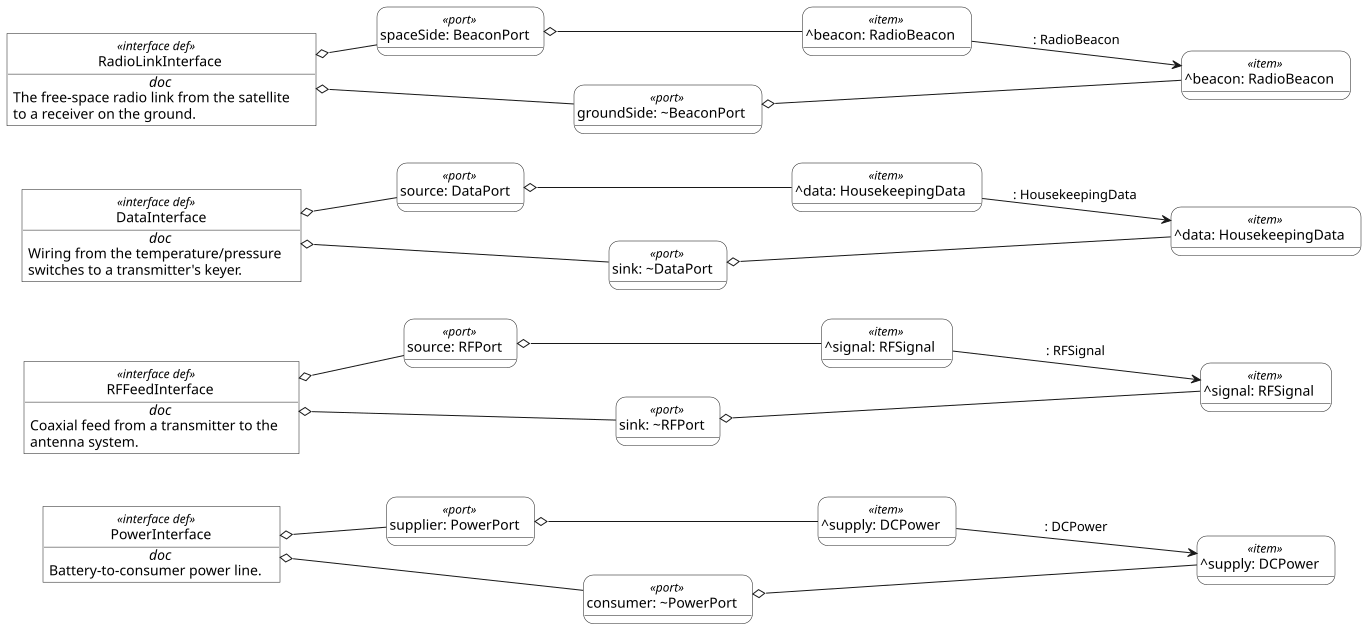

In [2]:
%viz --view=tree --style=LR SatelliteLibrary::PowerInterface SatelliteLibrary::RFFeedInterface SatelliteLibrary::DataInterface SatelliteLibrary::RadioLinkInterface

**1b. Value types, signals, the separation port and the calculation:**

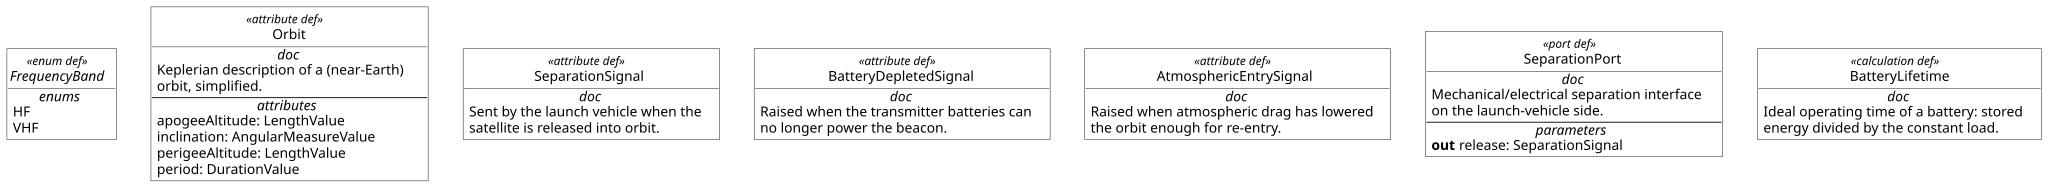

In [3]:
%viz --view=tree SatelliteLibrary::FrequencyBand SatelliteLibrary::Orbit SatelliteLibrary::SeparationSignal SatelliteLibrary::BatteryDepletedSignal SatelliteLibrary::AtmosphericEntrySignal SatelliteLibrary::SeparationPort SatelliteLibrary::BatteryLifetime

## 2. SatelliteBehavior — what the satellite does
Load the package:

In [4]:
/*
 * Simple Space Satellite — SysML v2 educational model
 * File 2 of 6: SatelliteBehavior
 *
 * WHAT the satellite does (actions / functions) and HOW it reacts over time
 * (state machines). Behaviour is defined independently of the hardware;
 * the structure package later says which part performs / exhibits it.
 */
package SatelliteBehavior {
	doc /* Functional (action) and state-based behaviour of the satellite. */

	private import ISQ::*;
	private import SatelliteLibrary::*;

	/* =====================================================================
	 * 1. Functions (action definitions) with inputs and outputs
	 * ===================================================================== */

	action def GenerateCarrier {
		doc /* Turn DC power into a stable radio-frequency carrier (an oscillator). */
		in item power : DCPower;
		out item carrier : RFSignal;
	}

	action def KeyPulses {
		doc /*
		 * Switch the carrier on and off to create the "beep" pulses. The pulse
		 * length depends on the housekeeping data (temperature / pressure).
		 */
		in item data : HousekeepingData;
		in item carrier : RFSignal;
		out item pulses : RFSignal;
	}

	action def RadiateSignal {
		doc /* Convert the conducted RF signal into a radiated electromagnetic wave. */
		in item signal : RFSignal;
		out item beacon : RadioBeacon;
	}

	action def TransmitBeacon {
		doc /* Top-level function of the satellite: tell the world it is in orbit. */
		in item power : DCPower;
		in item data : HousekeepingData;
		out item beacon : RadioBeacon;

		// Decomposition into sub-actions, connected by flows (an activity diagram in text)
		bind generate.power = power;
		action generate : GenerateCarrier { in item power; out item carrier; }

		flow from generate.carrier to key.carrier;
		bind key.data = data;
		action key : KeyPulses { in item data; in item carrier; out item pulses; }

		flow from key.pulses to radiate.signal;
		action radiate : RadiateSignal { in item signal; out item beacon; }
		bind radiate.beacon = beacon;
	}

	action def CirculateNitrogen {
		doc /* Run the internal fan so the nitrogen carries heat from the electronics to the shell. */
		in item power : DCPower;
	}

	/* =====================================================================
	 * 2. State machines
	 * ===================================================================== */

	state def MissionStates {
		doc /* Life cycle of the satellite from launch to re-entry. */

		first start then onLauncher;

		state onLauncher {
			doc /* Integrated under the fairing of the R-7 rocket; transmitters off. */
		}
		accept SeparationSignal
			then transmitting;

		state transmitting {
			doc /* Separated in orbit; the beacon is on (about 3 weeks for Sputnik 1). */
			do action beacon : TransmitBeacon;
		}
		accept BatteryDepletedSignal
			then silentInOrbit;

		state silentInOrbit {
			doc /* Batteries exhausted; the sphere keeps orbiting silently (tracked optically / by radar). */
		}
		accept AtmosphericEntrySignal
			then done;    // the satellite burns up: end of the state machine
	}

	state def ThermalStates {
		doc /*
		 * Simple bang-bang (thermostat) control of the internal temperature.
		 * Uses CHANGE triggers ("accept when <condition>") instead of signals.
		 */
		in measuredTemperature : TemperatureValue;
		in fanOnTemperature : TemperatureValue;
		in fanOffTemperature : TemperatureValue;

		first start then fanOff;

		state fanOff;
		accept when measuredTemperature > fanOnTemperature
			then fanOn;

		state fanOn {
			do action circulate : CirculateNitrogen;
		}
		accept when measuredTemperature < fanOffTemperature
			then fanOff;
	}
}


Comment (d825d0fc-820e-4127-9127-985d5da605b8)
Package SatelliteBehavior (425f29e5-7367-4edd-baa1-9dfdd303f078)


**Diagram 2a:** action flow of `TransmitBeacon`: power → *generate* → *key* (modulated by the housekeeping data) → *radiate* → beacon. Thick lines with `=` are `bind`s; arrows are `flow`s.

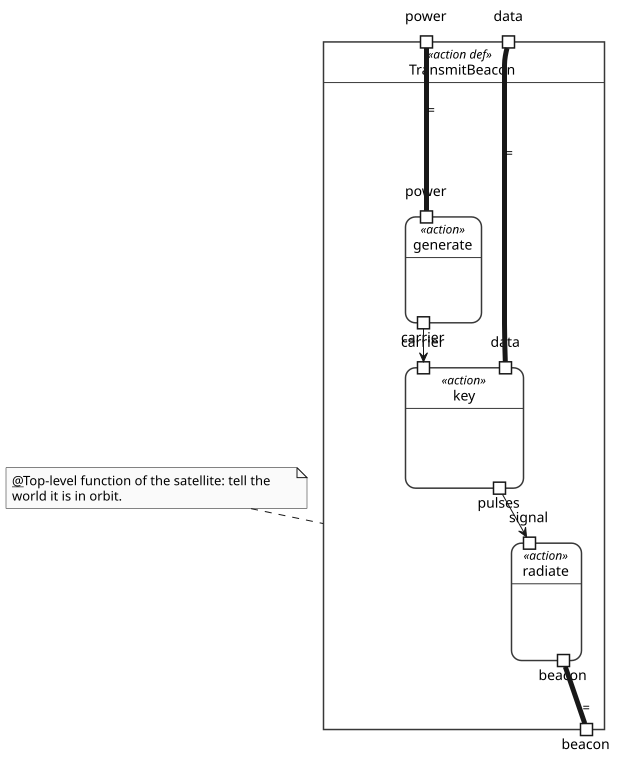

In [5]:
%viz --view=action SatelliteBehavior::TransmitBeacon

**Diagram 2b:** the two state machines: the mission life cycle (signal triggers) and the fan thermostat (change triggers `when …`).

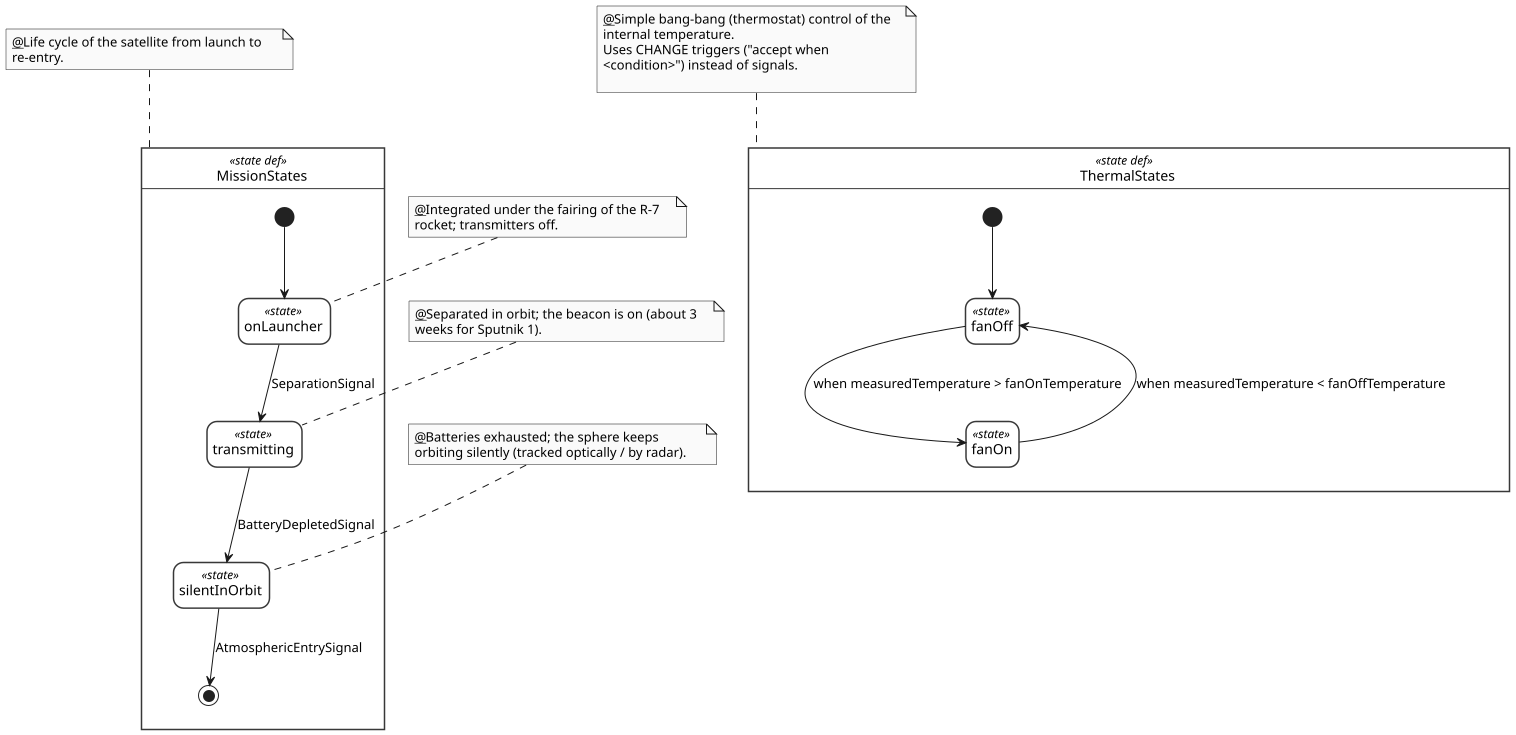

In [6]:
%viz --view=state SatelliteBehavior::MissionStates SatelliteBehavior::ThermalStates

## 3. SatelliteStructure — the physical architecture
Load the package:

In [7]:
/*
 * Simple Space Satellite — SysML v2 educational model
 * File 3 of 6: SatelliteStructure
 *
 * The physical architecture. It has two halves:
 *   A) PART DEFINITIONS – generic blueprints of the components and of a
 *      "simple satellite" (what parts it has and how they are wired);
 *   B) A PART USAGE  `sputnik1` – one concrete configuration of that
 *      blueprint, filled in with (approximate) Sputnik 1 values.
 */
package SatelliteStructure {
	doc /* Physical architecture of a Sputnik-1-like satellite. */

	private import ScalarValues::*;
	private import ISQ::*;
	private import SI::*;
	private import SatelliteLibrary::*;
	private import SatelliteBehavior::*;

	/* =====================================================================
	 * A) Component definitions
	 * ===================================================================== */

	part def Shell {
		doc /* Pressurised sphere made of two polished aluminium-alloy hemispheres. */
		attribute diameter : LengthValue;
		attribute wallThickness : LengthValue;
		attribute mass : MassValue;
		attribute internalPressure : PressureValue;   // nitrogen fill
	}

	part def InternalStructure {
		doc /* Internal frame, brackets, wiring and fasteners. */
		attribute mass : MassValue;
	}

	part def Battery {
		doc /* Silver-zinc primary (non-rechargeable) battery. */
		attribute mass : MassValue;
		attribute storedEnergy : EnergyValue;
		port powerOut : PowerPort;
	}

	part def Transmitter {
		doc /* Vacuum-tube radio transmitter that produces the pulsed beacon. */
		attribute mass : MassValue;
		attribute carrierFrequency : FrequencyValue;
		attribute band : FrequencyBand;
		attribute rfOutputPower : PowerValue;
		attribute dcInputPower : PowerValue;
		attribute pulseDuration : DurationValue;

		port powerIn : ~PowerPort;     // conjugated: receives power
		port dataIn : ~DataPort;       // conjugated: receives housekeeping data
		port rfOut : RFPort;

		perform action transmit : TransmitBeacon;   // this part carries out this function
	}

	part def Whip {
		doc /* One spring-loaded whip antenna element. */
		attribute whipLength : LengthValue;
	}

	part def AntennaSystem {
		doc /*
		 * Four whip antennas swept back from the sphere.
		 * Simplification: modelled as one system with one feed per transmitter.
		 */
		attribute mass : MassValue;
		part longWhips : Whip[2];
		part shortWhips : Whip[2];

		port feed20 : ~RFPort;
		port feed40 : ~RFPort;
		port radiated : BeaconPort;
	}

	part def ThermalControlUnit {
		doc /* Fan plus thermal switch: circulates nitrogen so the shell can radiate heat to space. */
		attribute mass : MassValue;
		attribute fanPower : PowerValue;
		attribute fanOnTemperature : TemperatureValue;
		attribute fanOffTemperature : TemperatureValue;
		port powerIn : ~PowerPort;

		perform action circulate : CirculateNitrogen;
	}

	part def SensorUnit {
		doc /* Temperature and pressure switches whose state changes the beacon pulse length. */
		attribute mass : MassValue;
		attribute internalTemperature : TemperatureValue;
		attribute internalPressure : PressureValue;
		port dataOut : DataPort;
	}

	/* =====================================================================
	 * A) The satellite blueprint: decomposition + internal wiring
	 * ===================================================================== */

	part def Satellite {
		doc /* A minimal satellite: a pressurised sphere, batteries, two beacons, antennas, a fan. */

		// ---- Key characteristics -------------------------------------------
		attribute orbit : Orbit;
		attribute beaconLifetime : DurationValue;   // result of an analysis (see SatelliteAnalysis)

		// Derived attribute: the mass roll-up is computed from the parts
		attribute totalMass : MassValue =
			shell.mass + structure.mass +
			txBatteryA.mass + txBatteryB.mass + fanBattery.mass +
			transmitter20.mass + transmitter40.mass +
			antennas.mass + thermalControl.mass + sensors.mass;

		// ---- Parts (composition) -------------------------------------------
		part shell : Shell;
		part structure : InternalStructure;
		part txBatteryA : Battery;          // powers the 20 MHz transmitter
		part txBatteryB : Battery;          // powers the 40 MHz transmitter
		part fanBattery : Battery;          // powers the thermal-control fan
		part transmitter20 : Transmitter;
		part transmitter40 : Transmitter;
		part antennas : AntennaSystem;
		part thermalControl : ThermalControlUnit;
		part sensors : SensorUnit;

		// ---- Boundary ports (how the satellite meets the outside world) ----
		port beaconOut : BeaconPort;
		port separationIn : ~SeparationPort;

		// ---- Internal connections (an internal block diagram in text) -----
		interface powerA : PowerInterface connect txBatteryA.powerOut to transmitter20.powerIn;
		interface powerB : PowerInterface connect txBatteryB.powerOut to transmitter40.powerIn;
		interface powerFan : PowerInterface connect fanBattery.powerOut to thermalControl.powerIn;

		interface data20 : DataInterface connect sensors.dataOut to transmitter20.dataIn;
		interface data40 : DataInterface connect sensors.dataOut to transmitter40.dataIn;

		interface rfFeed20 : RFFeedInterface connect transmitter20.rfOut to antennas.feed20;
		interface rfFeed40 : RFFeedInterface connect transmitter40.rfOut to antennas.feed40;

		// Delegate the antennas' radiating port to the satellite boundary port
		bind antennas.radiated = beaconOut;

		// ---- Behaviour exhibited by the whole satellite --------------------
		exhibit state missionStates : MissionStates;

		exhibit state thermalStates : ThermalStates {
			in measuredTemperature = sensors.internalTemperature;
			in fanOnTemperature = thermalControl.fanOnTemperature;
			in fanOffTemperature = thermalControl.fanOffTemperature;
		}
	}

	/* =====================================================================
	 * B) The concrete design: Sputnik 1 (PS-1), launched 4 October 1957
	 *    ":>>" means "redefines": we give values to features declared above.
	 *    Values marked (approx.) are illustrative estimates for teaching.
	 * ===================================================================== */

	part sputnik1 : Satellite {
		doc /* PS-1 ("Prosteyshiy Sputnik", "simplest satellite"), launched from Baikonur on 4 October 1957. */

		attribute :>> orbit {
			:>> perigeeAltitude = 215 [km];
			:>> apogeeAltitude = 939 [km];
			:>> inclination = 65.1 ['°'];
			:>> period = 96.2 [min];
		}

		part :>> shell {
			:>> diameter = 58 [cm];
			:>> wallThickness = 2 [mm];
			:>> mass = 14.0 [kg];                  // (approx.)
			:>> internalPressure = 131.7E3 [Pa];   // about 1.3 atm of nitrogen
		}

		part :>> structure {
			:>> mass = 10.0 [kg];                  // (approx.)
		}

		// Three silver-zinc batteries, 51 kg in total (approx. 17 kg each)
		part :>> txBatteryA { :>> mass = 17 [kg]; :>> storedEnergy = 7 [MJ]; }   // energy (approx.)
		part :>> txBatteryB { :>> mass = 17 [kg]; :>> storedEnergy = 7 [MJ]; }   // energy (approx.)
		part :>> fanBattery { :>> mass = 17 [kg]; :>> storedEnergy = 7 [MJ]; }   // energy (approx.)

		part :>> transmitter20 {
			:>> carrierFrequency = 20.005E6 [Hz];
			:>> band = FrequencyBand::HF;
			:>> rfOutputPower = 1 [W];
			:>> dcInputPower = 3.5 [W];            // (approx.)
			:>> pulseDuration = 0.3 [s];
			:>> mass = 1.75 [kg];                  // (approx.)
		}

		part :>> transmitter40 {
			:>> carrierFrequency = 40.002E6 [Hz];
			:>> band = FrequencyBand::VHF;
			:>> rfOutputPower = 1 [W];
			:>> dcInputPower = 3.5 [W];            // (approx.)
			:>> pulseDuration = 0.3 [s];
			:>> mass = 1.75 [kg];                  // (approx.)
		}

		part :>> antennas {
			:>> mass = 2.0 [kg];                   // (approx.)
			part :>> longWhips { :>> whipLength = 2.9 [m]; }
			part :>> shortWhips { :>> whipLength = 2.4 [m]; }
		}

		part :>> thermalControl {
			:>> mass = 2.5 [kg];                   // (approx.)
			:>> fanPower = 1 [W];                  // (approx.)
			:>> fanOnTemperature = 309.15 [K];     // 36 °C
			:>> fanOffTemperature = 293.15 [K];    // 20 °C
		}

		part :>> sensors {
			:>> mass = 0.6 [kg];                   // (approx.)
		}
		// totalMass = 14 + 10 + 3*17 + 2*1.75 + 2 + 2.5 + 0.6 = 83.6 kg (the historical value)
	}
}


Comment (66e3643a-e792-4179-99e0-06645a6dbb5d)
Package SatelliteStructure (57e7817d-0844-4d2d-9e20-8b3fe8dff4ff)


**Diagram 3a:** interconnection view (the SysML v2 equivalent of an internal block diagram) of the `Satellite` blueprint: batteries → transmitters → antennas → boundary port `beaconOut`, plus the sensor data lines.

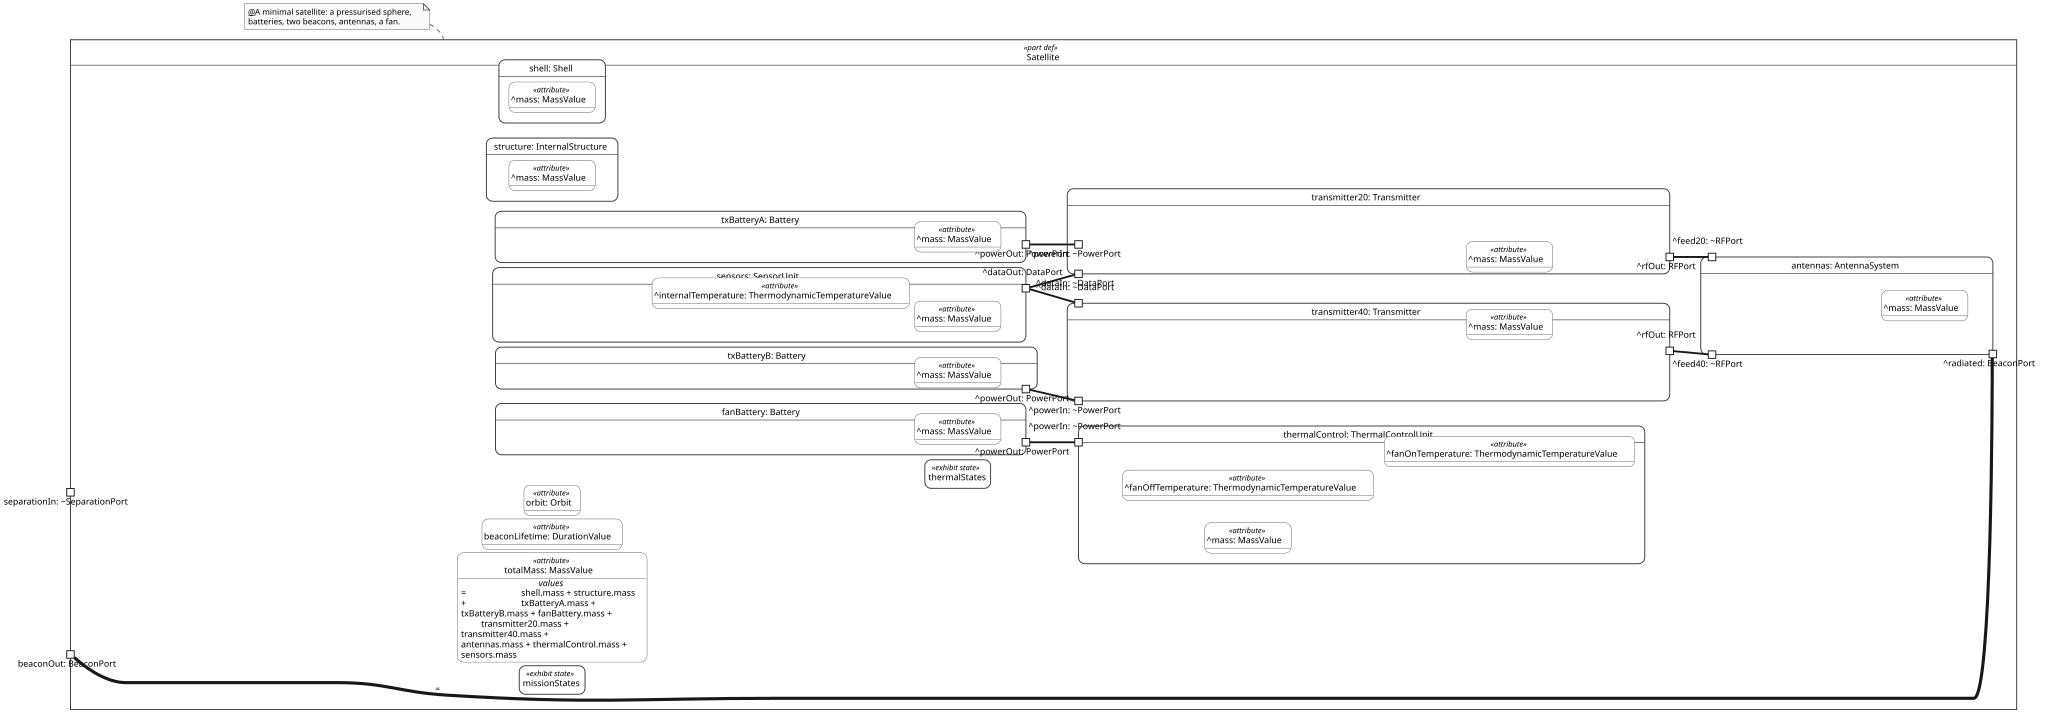

In [8]:
%viz --view=interconnection --style=LR SatelliteStructure::Satellite

*Alternative layout (top-to-bottom) of the same diagram, for comparison:*

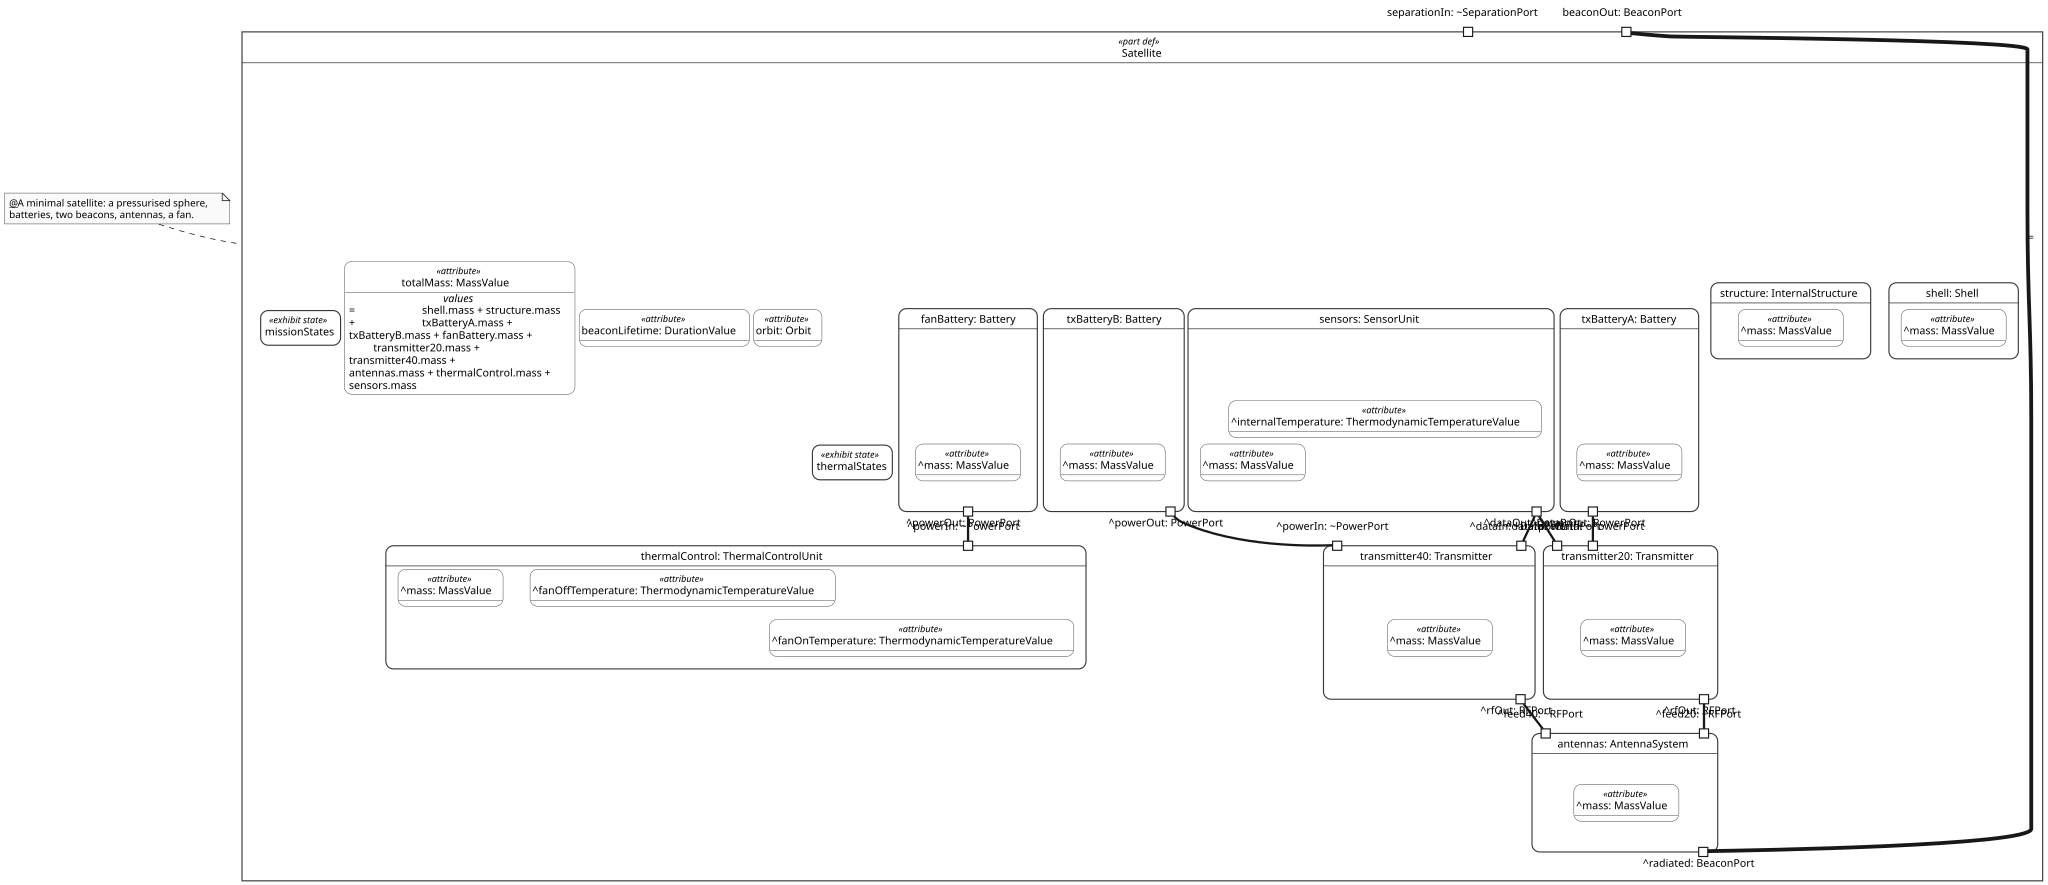

In [9]:
%viz --view=interconnection SatelliteStructure::Satellite

**Diagram 3b:** the concrete design `sputnik1` as a tree, with the values given by redefinition (`:>>`).

*Note:* the pilot implementation stops after 1000 model elements and may print an "EXCEEDS THE LIMIT" banner here; the diagram is still complete.

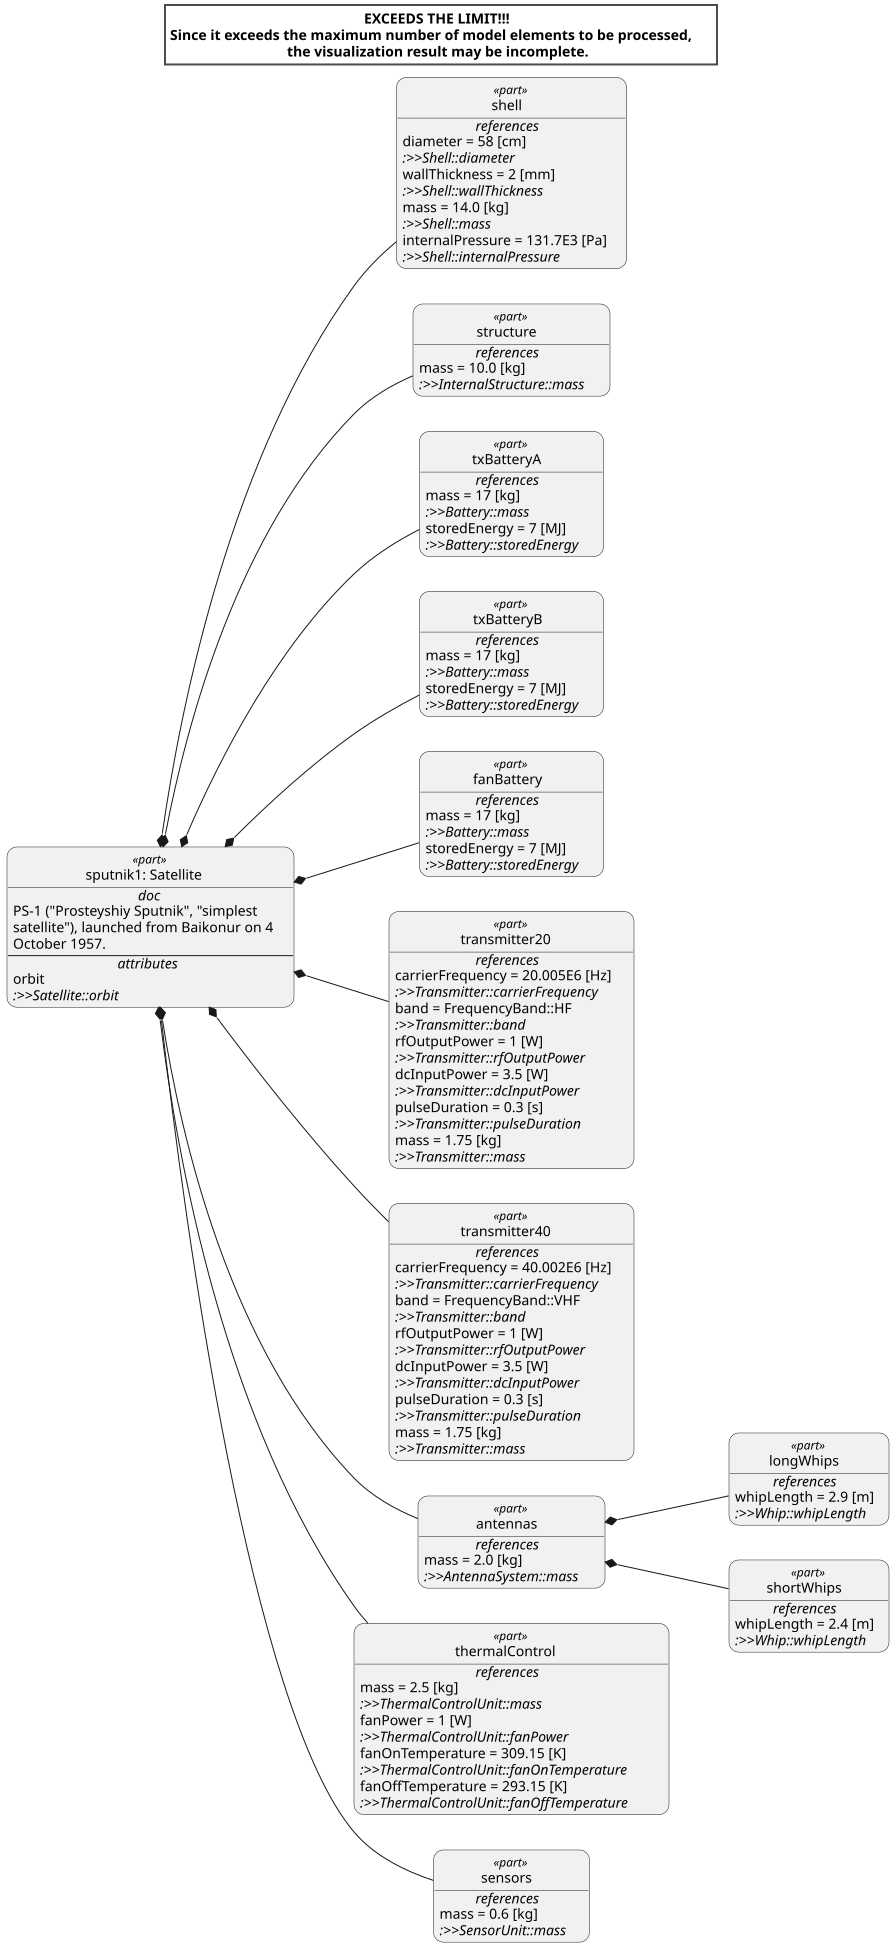

In [10]:
%viz --view=tree --style=LR SatelliteStructure::sputnik1

## 4. SatelliteRequirements — what the satellite must do
Load the package:

In [11]:
/*
 * Simple Space Satellite — SysML v2 educational model
 * File 4 of 6: SatelliteRequirements
 *
 * Requirements in SysML v2 are constraints with a SUBJECT (the thing that
 * must comply). They can carry formal, checkable constraints ("require
 * constraint { ... }") or be purely textual (only a "doc").
 * Pattern used here:  requirement def  ->  requirement usage (with values)
 *                      -> requirement group (the specification).
 */
package SatelliteRequirements {
	doc /* Stakeholder and system requirements for a "simplest satellite". */

	private import ISQ::*;
	private import SI::*;
	private import SatelliteLibrary::*;
	private import SatelliteStructure::*;

	/* =====================================================================
	 * 1. Requirement definitions (reusable, parameterised)
	 * ===================================================================== */

	requirement def MassRequirement {
		doc /* The total mass of the satellite shall not exceed the allowed launch mass. */
		subject sat : Satellite;
		attribute maxMass : MassValue;
		require constraint { sat.totalMass <= maxMass }
	}

	requirement def EnvelopeRequirement {
		doc /* The satellite (antennas folded) shall fit inside the launcher fairing. */
		subject sat : Satellite;
		attribute maxDiameter : LengthValue;
		require constraint { sat.shell.diameter <= maxDiameter }
	}

	requirement def BeaconFrequencyRequirement {
		doc /*
		 * The satellite shall transmit on two frequencies, one in the HF band near
		 * 20 MHz and one in the VHF band near 40 MHz, so that it can be received
		 * by radio amateurs world-wide.
		 */
		subject sat : Satellite;
		attribute tolerance : FrequencyValue;
		require constraint {
			sat.transmitter20.band == FrequencyBand::HF and
			sat.transmitter40.band == FrequencyBand::VHF and
			sat.transmitter20.carrierFrequency >= 20E6 [Hz] - tolerance and
			sat.transmitter20.carrierFrequency <= 20E6 [Hz] + tolerance and
			sat.transmitter40.carrierFrequency >= 40E6 [Hz] - tolerance and
			sat.transmitter40.carrierFrequency <= 40E6 [Hz] + tolerance
		}
	}

	requirement def LifetimeRequirement {
		doc /* The beacon shall operate for at least the minimum mission duration. */
		subject sat : Satellite;
		attribute minLifetime : DurationValue;
		require constraint { sat.beaconLifetime >= minLifetime }
	}

	requirement def ThermalRequirement {
		doc /* The internal temperature shall be kept within the operating range of the electronics. */
		subject sat : Satellite;
		attribute minTemperature : TemperatureValue;
		attribute maxTemperature : TemperatureValue;
		require constraint {
			sat.thermalControl.fanOffTemperature >= minTemperature and
			sat.thermalControl.fanOnTemperature <= maxTemperature
		}
	}

	requirement def TelemetryRequirement {
		doc /*
		 * The beacon shall convey the internal temperature and pressure of the
		 * satellite to ground observers. (A purely textual requirement.)
		 */
		subject sat : Satellite;
	}

	/* =====================================================================
	 * 2. Requirement usages (with concrete values and IDs <'...'>)
	 * ===================================================================== */

	requirement <'SAT-1'> massLimit : MassRequirement {
		subject sat : Satellite;
		attribute :>> maxMass = 90 [kg];
	}

	requirement <'SAT-2'> envelopeLimit : EnvelopeRequirement {
		subject sat : Satellite;
		attribute :>> maxDiameter = 60 [cm];
	}

	requirement <'SAT-3'> beaconFrequencies : BeaconFrequencyRequirement {
		subject sat : Satellite;
		attribute :>> tolerance = 0.1E6 [Hz];
	}

	requirement <'SAT-4'> minimumLifetime : LifetimeRequirement {
		subject sat : Satellite;
		attribute :>> minLifetime = 14 [d];
	}

	requirement <'SAT-5'> thermalRange : ThermalRequirement {
		subject sat : Satellite;
		attribute :>> minTemperature = 273.15 [K];   //  0 °C
		attribute :>> maxTemperature = 323.15 [K];   // 50 °C
	}

	requirement <'SAT-6'> housekeepingTelemetry : TelemetryRequirement {
		subject sat : Satellite;
	}

	/* =====================================================================
	 * 3. The specification: a group of requirements on one subject
	 * ===================================================================== */

	requirement <'SAT'> satelliteSpecification {
		doc /* System specification of the simplest satellite. */
		subject sat : Satellite;

		require massLimit;
		require envelopeLimit;
		require beaconFrequencies;
		require minimumLifetime;
		require thermalRange;
		require housekeepingTelemetry;
	}
}


Comment (6dd7e195-0b37-48a0-82f5-aff32ecb8d2a)
Package SatelliteRequirements (cc6383f6-80f6-47a5-8b69-bdf4b7f733d6)


**Diagram:** requirement definitions (with their `require constraint`s), the requirement usages SAT-1 … SAT-6 with their values, and the `satelliteSpecification` group that requires them all.

**4a. The specification** (the group of requirements):

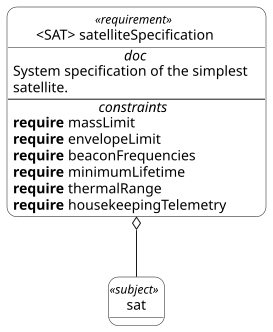

In [12]:
%viz --view=tree SatelliteRequirements::satelliteSpecification

**4b. SAT-1 … SAT-3** with their definitions and constraints:

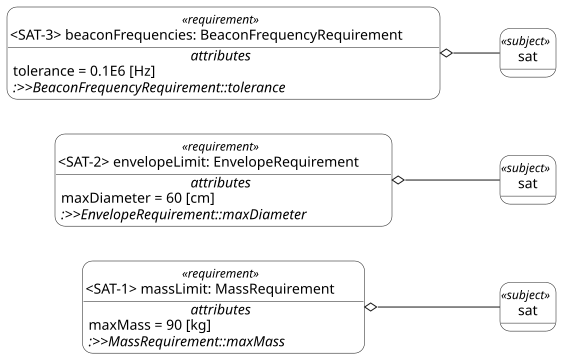

In [13]:
%viz --view=tree --style=LR SatelliteRequirements::massLimit SatelliteRequirements::envelopeLimit SatelliteRequirements::beaconFrequencies

**4c. SAT-4 … SAT-6:**

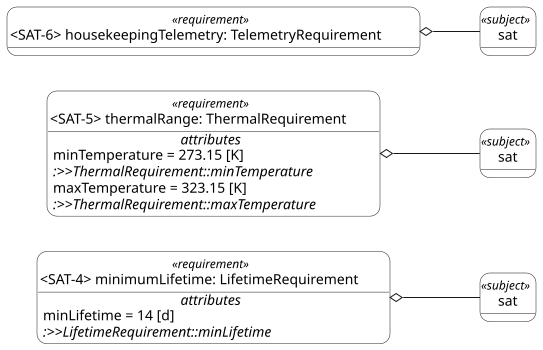

In [14]:
%viz --view=tree --style=LR SatelliteRequirements::minimumLifetime SatelliteRequirements::thermalRange SatelliteRequirements::housekeepingTelemetry

## 5. SatelliteMissionContext — the satellite in its environment
Load the package:

In [15]:
/*
 * Simple Space Satellite — SysML v2 educational model
 * File 5 of 6: SatelliteMissionContext
 *
 * The satellite in its environment: the launch vehicle that releases it,
 * the ground stations that listen to it, and the use case that explains
 * WHY the system exists.
 */
package SatelliteMissionContext {
	doc /* Operational context and use case of the satellite mission. */

	private import ScalarValues::*;
	private import SatelliteLibrary::*;
	private import SatelliteStructure::*;

	/* =====================================================================
	 * 1. External systems (actors)
	 * ===================================================================== */

	part def LaunchVehicle {
		doc /* The R-7 (8K71PS) rocket that placed the satellite into orbit. */
		port separationOut : SeparationPort;

		action releasePayload {
			send new SeparationSignal() via separationOut;
		}
	}

	part def GroundStation {
		doc /* Any radio receiver on Earth: Soviet tracking stations and amateurs around the world. */
		attribute location : String;
		port beaconIn : ~BeaconPort;
	}

	/* =====================================================================
	 * 2. Use case: why the satellite exists
	 * ===================================================================== */

	use case def 'Announce Presence in Orbit' {
		subject sat : Satellite;
		actor rocket : LaunchVehicle;
		actor listeners : GroundStation[1..*];

		objective {
			doc /*
			 * Demonstrate that an artificial satellite has reached orbit, in a way that
			 * anyone with a short-wave receiver can verify, and learn about the upper
			 * atmosphere and ionosphere from the received signal.
			 */
		}
	}

	/* =====================================================================
	 * 3. The mission context: system of interest + environment, connected
	 * ===================================================================== */

	part sputnikMission {
		doc /* The October 1957 mission: rocket, satellite and listeners on the ground. */

		part launcher : LaunchVehicle;
		part satellite :> sputnik1;
		part listeningStations : GroundStation[1..*];

		connect launcher.separationOut to satellite.separationIn;

		interface radioLink : RadioLinkInterface
			connect satellite.beaconOut to listeningStations.beaconIn;

		use case announce : 'Announce Presence in Orbit' {
			subject sat = satellite;
			actor rocket = launcher;
			actor listeners = listeningStations;
		}
	}
}


Comment (0bd493d9-c388-4844-8a81-ccb3d64c201b)
Package SatelliteMissionContext (6b46fb35-2738-4815-b865-a8a9877c3805)


**Diagram 5a:** the use case: subject (the satellite) and actors (rocket, listening stations).

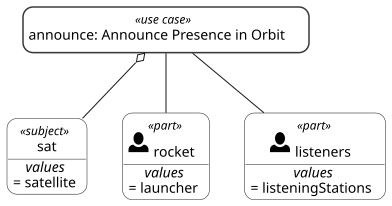

In [16]:
%viz --view=case SatelliteMissionContext::sputnikMission::announce

**Diagram 5b:** the mission context: launcher → satellite (separation) → ground stations (radio link).

*Note:* this view may also show the "EXCEEDS THE LIMIT" banner because it walks into `sputnik1`; the diagram is still complete.

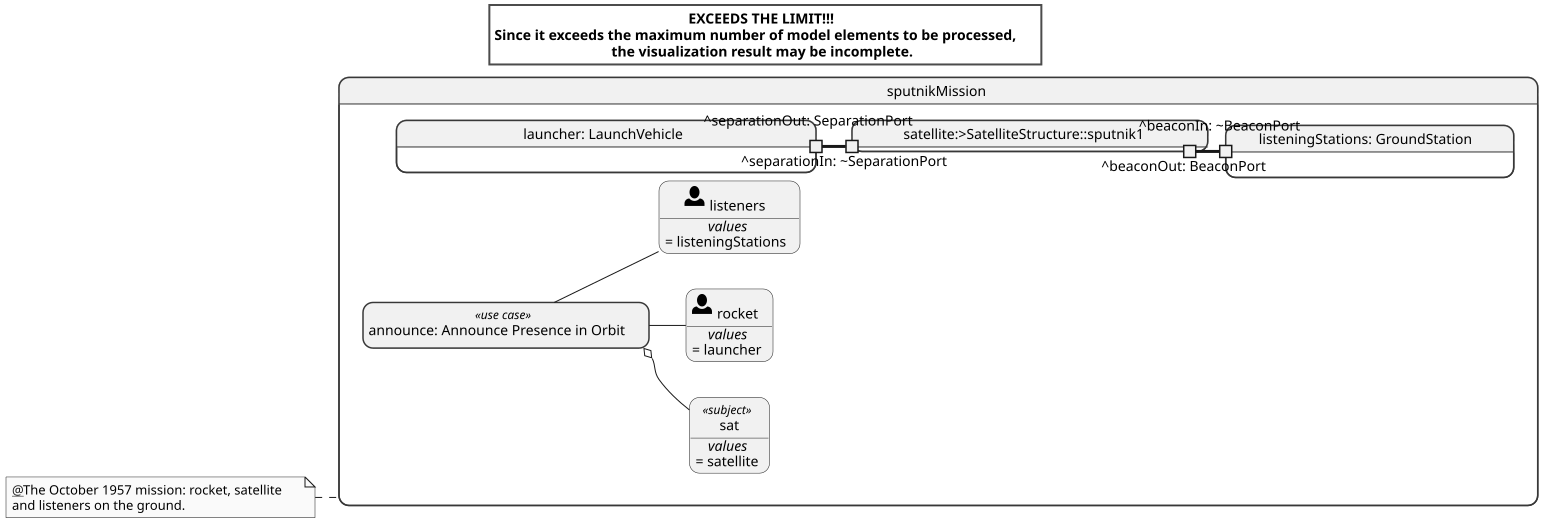

In [17]:
%viz --view=interconnection --style=LR SatelliteMissionContext::sputnikMission

## 6. SatelliteAnalysis — does the design meet the requirements?
Load the package:

In [18]:
/*
 * Simple Space Satellite — SysML v2 educational model
 * File 6 of 6: SatelliteAnalysis
 *
 * Closing the loop: does the design meet its requirements?
 *   - an ANALYSIS case computes the beacon lifetime from the battery energy;
 *   - a VERIFICATION case describes how the mass requirement is tested;
 *   - SATISFY relationships state that the design meets the specification.
 */
package SatelliteAnalysis {
	doc /* Analyses, verification cases and requirement satisfaction for Sputnik 1. */

	private import ISQ::*;
	private import SI::*;
	private import SatelliteLibrary::*;
	private import SatelliteStructure::*;
	private import SatelliteRequirements::*;

	/* =====================================================================
	 * 1. Analysis case: how long can the beacon transmit?
	 * ===================================================================== */

	analysis def BeaconLifetimeAnalysis {
		doc /*
		 * Each transmitter has its own battery. The beacon lifetime is that of
		 * the battery/transmitter chain that runs out first.
		 */
		subject sat : Satellite;

		objective lifetimeObjective {
			doc /* Determine the beacon lifetime and check it against requirement SAT-4. */
			require constraint { predictedLifetime >= minimumLifetime.minLifetime }
		}

		calc chainA : BatteryLifetime {
			in energy = sat.txBatteryA.storedEnergy;
			in load = sat.transmitter20.dcInputPower;
		}

		calc chainB : BatteryLifetime {
			in energy = sat.txBatteryB.storedEnergy;
			in load = sat.transmitter40.dcInputPower;
		}

		return predictedLifetime : DurationValue =
			if chainA.lifetime < chainB.lifetime ? chainA.lifetime else chainB.lifetime;
		// Sputnik 1 (approx. values): 7 MJ / 3.5 W = 2.0E6 s, about 23 days
		// (historically the beacon fell silent after 22 days, on 26 October 1957).
	}

	/* =====================================================================
	 * 2. Verification case: weigh the flight article
	 * ===================================================================== */

	verification def SatelliteWeighingTest {
		doc /* Verify requirement SAT-1 by measuring the mass of the satellite on a scale. */
		private import VerificationCases::*;

		subject testSatellite : Satellite;

		objective weighingObjective {
			verify massLimit;
		}

		action weigh {
			in part testSatellite : Satellite = SatelliteWeighingTest::testSatellite;
			out measuredMass : MassValue;
		}

		action evaluate {
			in measuredMass : MassValue = weigh.measuredMass;
			out verdict : VerdictKind = PassIf(measuredMass <= massLimit.maxMass);
		}

		return verdict : VerdictKind = evaluate.verdict;
	}

	/* =====================================================================
	 * 3. Design context: run the analysis and claim satisfaction
	 * ===================================================================== */

	part sputnikDesignContext {
		doc /* Binds the analysis results to the design and states which requirements it satisfies. */

		analysis lifetimeAnalysis : BeaconLifetimeAnalysis {
			subject sat = design;
		}

		part design :> sputnik1 {
			attribute :>> beaconLifetime = lifetimeAnalysis.predictedLifetime;
		}

		verification weighing : SatelliteWeighingTest {
			subject testSatellite :> design;
		}

		satisfy satelliteSpecification by design;
	}
}


Comment (8a62ce32-3faf-44e4-99bc-52fb4eea7ef0)
Package SatelliteAnalysis (9a53f1bc-af24-4850-8ff8-32ad83642dcb)


**Diagram:** case view of the beacon-lifetime analysis (subject, objective, the two battery-chain calculations, result) and of the weighing verification case (subject, `verify massLimit`, actions, verdict).

**6a. Analysis case:**

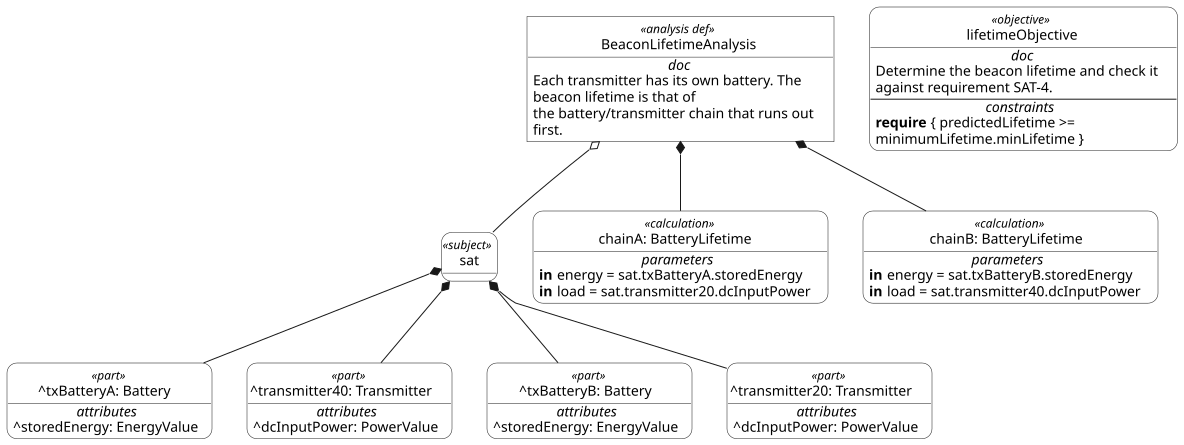

In [23]:
%viz --view=case SatelliteAnalysis::BeaconLifetimeAnalysis

**6b. Verification case:**

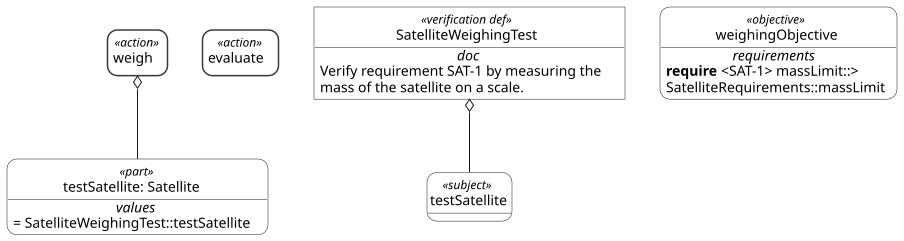

In [20]:
%viz --view=case SatelliteAnalysis::SatelliteWeighingTest

## Useful commands
`%list SatelliteStructure::*` lists elements, `%show <name>` prints the model tree of an element, `%help` lists all magic commands.

In [21]:
%show SatelliteStructure::sputnik1

PartUsage sputnik1 (b9005d2a-a3d2-4913-8066-ff36fd374661)
  [Subsetting (implicit)] PartUsage parts (0c6a9942-4bb9-58da-8344-57ecd220d4de)
  [FeatureTyping] PartDefinition Satellite (af9e3e1c-8ac0-4ce7-8b8a-0788193502bd)
  [OwningMembership] Documentation (eff62930-a9f4-42bc-9d77-586bd3c21f2e)
  [FeatureMembership] AttributeUsage orbit (cc143365-35eb-4509-8fac-a6496496798d)
    [Redefinition] AttributeUsage orbit (07a4c65b-6cd5-4271-8d6f-36bdf8f844ae)
    [FeatureMembership] ReferenceUsage perigeeAltitude (d71b78d2-15b5-41d2-ac6c-812a2a5c7eee)
      [Redefinition] AttributeUsage perigeeAltitude (78e3ee30-5e1e-4642-9e5b-a6f57fabe96f)
      [FeatureValue] OperatorExpression [ (8e2d8473-4784-4030-9dff-57828d46d2dd)
        [ReturnParameterMembership] Feature result (2812d5c7-6ff8-48f1-ab52-7d4f9a20618f)
    [FeatureMembership] ReferenceUsage apogeeAltitude (fede09cf-62aa-4081-abda-0125c2392973)
      [Redefinition] AttributeUsage apogeeAltitude (d041f6bd-705b-44ef-946e-359eecfa5ba8)
     